In [1]:
import torch
import torch.nn.functional as F
import matplotlib.pyplot as plt
import random

In [2]:
words = open("names.txt", 'r').read().splitlines()

chars = sorted(list(set("".join(words))))
stoi = {s:i+1 for i, s in enumerate(chars)}
stoi['.'] = 0
itos = {i:s for s,i in stoi.items()}


In [3]:
block_size = 3
def build_dataset(words):
    X = []
    Y = []

    for word in words:
        context = [0] * block_size
        ##print(word)
        for ch in word + '.':
            ix = stoi[ch]
            X.append(context)
            Y.append(ix)
            ##print(f"{"".join([itos[i] for i in context])} ----> {ch}" )
            context = context[1:] + [ix]
            
    X = torch.tensor(X)
    Y = torch.tensor(Y)
    return X, Y


random.seed(42)
random.shuffle(words)
n1 = int(0.8 * len(words))
n2 = int(0.9 * len(words))
Xtr, Ytr = build_dataset(words[:n1])
Xdev, Ydev = build_dataset(words[n1:n2])
Xte, Yte = build_dataset(words[n2:]) #test
Xdev.shape

torch.Size([22655, 3])

Shift + Enter 运行并到下一个
Ctrl + Enter  只运行当前 cell
Esc + B       下面新建 cell
Esc + A       上面新建 cell
Esc + M       变 Markdown
Esc + Y       变 Code

In [11]:
g = torch.Generator().manual_seed(2147483647)
EMBEDDING_NUMBER = 2 
NEURONS_NUMBER = 200
C = torch.randn(size=[27, EMBEDDING_NUMBER],                                )
W1 = torch.randn(block_size * EMBEDDING_NUMBER, NEURONS_NUMBER, generator=g )
b1 = torch.randn(NEURONS_NUMBER,                                generator=g)
W2 = torch.randn(NEURONS_NUMBER, 27,                            generator=g ) * 0.01
b2 = torch.randn(27,                                            generator=g) * 0
parameters = [C, W1, b1, W2, b2]

for p in parameters:
    p.requires_grad = True

In [19]:
sum(p.nelement() for p in parameters) # number of parameters in total

6881

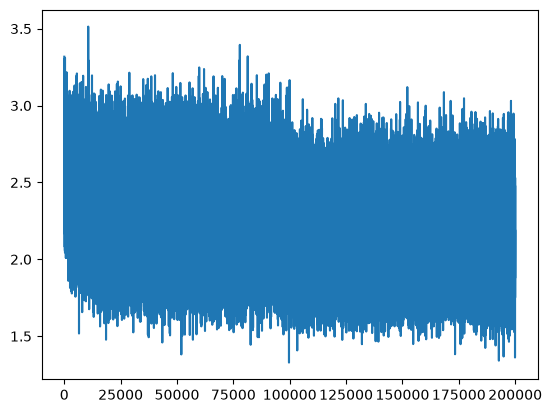

In [12]:
lre = torch.linspace(-3, 0, 1000)
lrs = 10 ** lre
lri = []
lossi = []
stepi = []
for i in range(200000):
    #minibatch construct
    ix = torch.randint(0, Xtr.shape[0], size=(32, ))

    #forward pass
    emb = C[Xtr[ix]]
    #emb shape [16, 3, 2]  -->>> [16, 6]

    emb = emb.view(-1, block_size * EMBEDDING_NUMBER)
        #还有两种emb 的方法，但是会创建新变量 然后在复制
    h = torch.tanh(emb @ W1 + b1)

    logits = h @ W2 + b2

    parameters = [C, W1, b1, W2, b2]

    #count loss
    loss = F.cross_entropy(logits, Ytr[ix])
    
    # zero grad
    for p in parameters:
        p.grad = None

    #backward
    loss.backward()

    #update

        #lr = lrs[i]
    lr = 0.1 if i < 100000 else 0.01
        
    for p in parameters:
        p.data -= lr * p.grad

    # track stats
    #lri.append(lre[i])
    stepi.append(i)
    lossi.append(loss.item())

plt.plot(stepi, lossi)


1.328555703163147


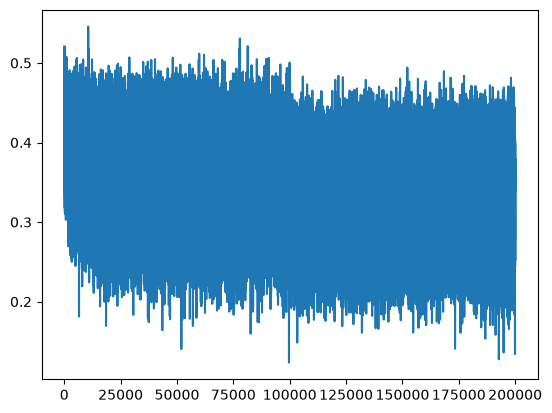

In [14]:
plt.plot(stepi, torch.tensor(lossi).log10())
print(min(lossi))

In [15]:
emb = C[Xtr]
h = torch.tanh(emb.view(-1, block_size * EMBEDDING_NUMBER) @ W1 + b1)
logits = h @ W2 + b2

loss = F.cross_entropy(logits, Ytr)
print(loss)

tensor(2.1549, grad_fn=<NllLossBackward0>)


In [16]:

emb = C[Xdev]
h = torch.tanh(emb.view(-1, block_size * EMBEDDING_NUMBER) @ W1 + b1)
logits = h @ W2 + b2

loss = F.cross_entropy(logits, Ydev)
print(loss)

tensor(2.1808, grad_fn=<NllLossBackward0>)


In [ ]:
"""  比手写更加稳定 不会overflow （inf） 更快内置计算方法
logits
↓
softmax  把一组任意实数的 logits，变成一组合法的概率。
↓
取正确类别的概率 (cross_entropy 包含了算softmax)
↓
-log
↓
mean"""

'  比手写更加稳定 不会overflow （inf） 更快内置计算方法\nlogits\n↓\nsoftmax  把一组任意实数的 logits，变成一组合法的概率。\n↓\n取正确类别的概率 (cross_entropy 包含了算softmax)\n↓\n-log\n↓\nmean'

In [17]:
emb = C[Xte]
h = torch.tanh(emb.view(-1, block_size * EMBEDDING_NUMBER) @ W1 + b1)
logits = h @ W2 + b2

loss = F.cross_entropy(logits, Yte)
print(loss)

tensor(2.1806, grad_fn=<NllLossBackward0>)


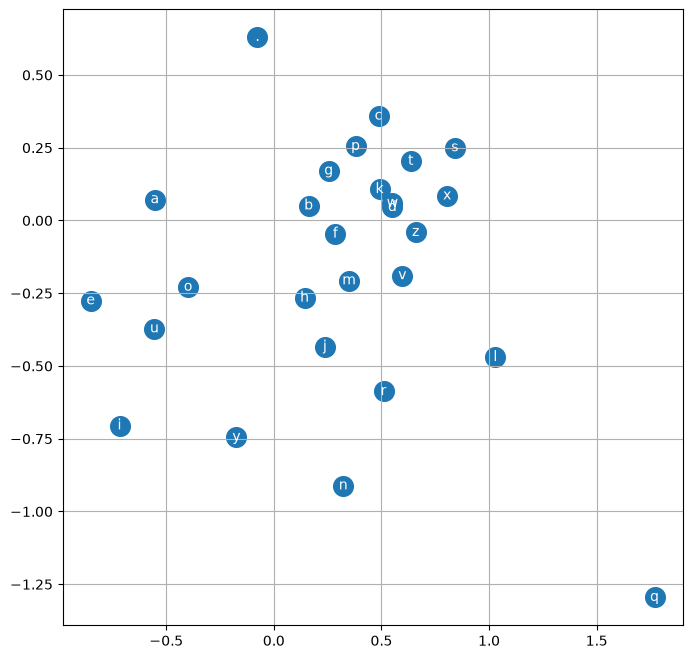

In [ ]:
# visualize dimensions 0 and 1 of the embedding matrix C for all characters
plt.figure(figsize=(8,8))
plt.scatter(C[:,0].data, C[:,1].data, s=200)
for i in range(C.shape[0]):
    plt.text(C[i,0].item(), C[i,1].item(), itos[i], ha="center", va="center", color='white')
plt.grid('minor')

In [18]:
# sample from the model
g = torch.Generator().manual_seed(2147483647 + 10)
for i in range(20):
    context = [0] * block_size
    out = []
    while True:
        emb = C[torch.tensor([context])] 
        h = torch.tanh(emb.view(-1, block_size * EMBEDDING_NUMBER) @ W1 + b1)
        logits = h @ W2 + b2
        prob = F.softmax(logits, dim= 1)

        ix = (torch.multinomial(prob, num_samples=1, replacement=True, generator=g)).item()

        out.append(itos[ix])
        if ix == 0:
            break
        context = context[1:] + [ix]

    print("".join(out))

carlah.
amillie.
hicklyn.
thil.
skanden.
jazonte.
delynn.
jarqui.
nellara.
chaiivia.
leigh.
ham.
prin.
quint.
shoine.
livabiuwa.
elogiearyxix.
kaellinslee.
dae.
isa.


... ----> j
1. words -> X, Y (stoi, itos)
2. C [27, 2] is a table (eg. C[1] -> [0.8, 2.1])
3. C[X] --- [32, 3, 2]
4. embedding ---  view [32, 6] 
5. 把embedding W1 和 b1 注意broadcast 和W1 has 6 inputs and neurons= 100 [6 , 100]
6. hidden layers tanh 100inputs and 100 outputs
7. output layer takes 100 inputs and 27 outputs(the outcome is logits) h @ W2 + b2
8. forwardpass -> loss (cross_entropy(logits, Y) and softmax) softmax takes logits and outputs prob, cros_entropy includes softmax while count the loss
9. minibatch take 32 samples to train model each time 
    ix randint  (X[ix])
10. use linspace to test different learning rates 
11. def build_dataset()    train/dev/test  0.8/0.1/0.1
dev is used to findthe best embedding number or tanh or other hyper parameters

